In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

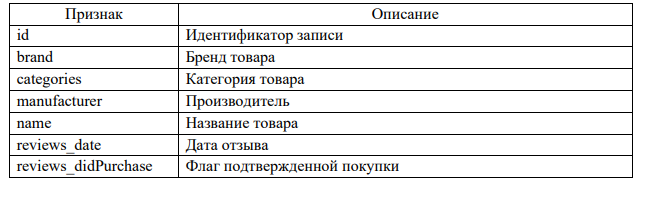
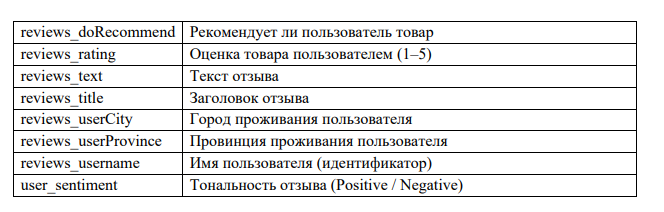

In [2]:
df = pd.read_csv('data_with_review.csv')

In [16]:
df.info()

<class 'pandas.DataFrame'>
Index: 27230 entries, 3 to 29999
Data columns (total 12 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   brand                27230 non-null  str   
 1   categories           27230 non-null  str   
 2   manufacturer         27230 non-null  str   
 3   name                 27230 non-null  str   
 4   reviews_date         27230 non-null  str   
 5   reviews_didPurchase  27230 non-null  object
 6   reviews_doRecommend  27230 non-null  object
 7   reviews_rating       27230 non-null  int64 
 8   reviews_text         27230 non-null  str   
 9   reviews_title        27230 non-null  str   
 10  reviews_username     27230 non-null  str   
 11  user_sentiment       27230 non-null  str   
dtypes: int64(1), object(2), str(9)
memory usage: 17.5+ MB


In [3]:
round(df.isnull().sum() / len(df) * 100, 3)

id                       0.000
brand                    0.000
categories               0.000
manufacturer             0.470
name                     0.000
reviews_date             0.153
reviews_didPurchase     46.893
reviews_doRecommend      8.567
reviews_rating           0.000
reviews_text             0.000
reviews_title            0.633
reviews_userCity        93.570
reviews_userProvince    99.433
reviews_username         0.210
user_sentiment           0.003
dtype: float64

In [4]:
df.duplicated().sum()

np.int64(0)

In [5]:
df.drop(['id', 'reviews_userCity','reviews_userProvince'], axis=1, inplace=True)

In [6]:
df['reviews_didPurchase'] = df['reviews_didPurchase'].fillna('Unkown')

In [7]:
df.dropna(inplace=True)

In [8]:
round(df.isnull().sum() / len(df) * 100, 3)

brand                  0.0
categories             0.0
manufacturer           0.0
name                   0.0
reviews_date           0.0
reviews_didPurchase    0.0
reviews_doRecommend    0.0
reviews_rating         0.0
reviews_text           0.0
reviews_title          0.0
reviews_username       0.0
user_sentiment         0.0
dtype: float64

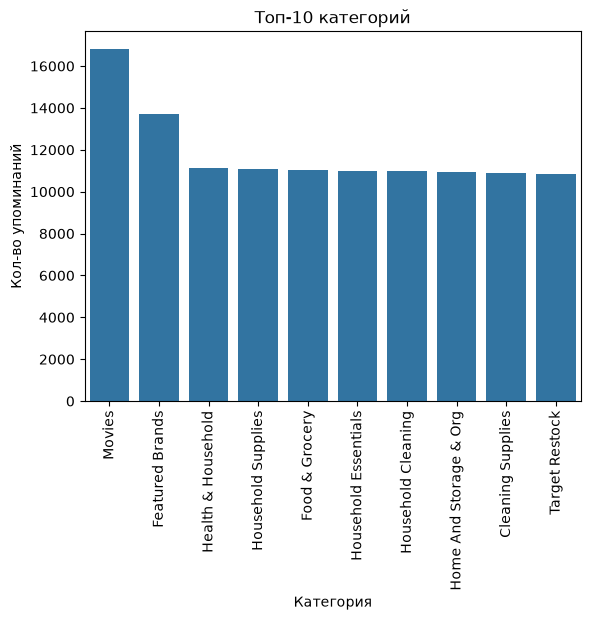

In [9]:
categories_used = {}
for cat_list in df['categories']:
    cats = cat_list.split(',')
    for category in cats:
        categories_used[category] = categories_used.get(category, 0)
        categories_used[category] += 1
lst_of_car = dict(sorted(categories_used.items(), key=lambda n: n[1], reverse=True))
sns.barplot(x=list(lst_of_car.keys())[:10], y=list(lst_of_car.values())[:10])
plt.xticks(rotation=90)
plt.ylabel('Кол-во упоминаний')
plt.xlabel('Категория')
plt.title('Топ-10 категорий');

In [10]:
the_most_recomended = df.groupby('name').agg({'reviews_doRecommend': 'sum'}).sort_values('reviews_doRecommend', ascending=False)

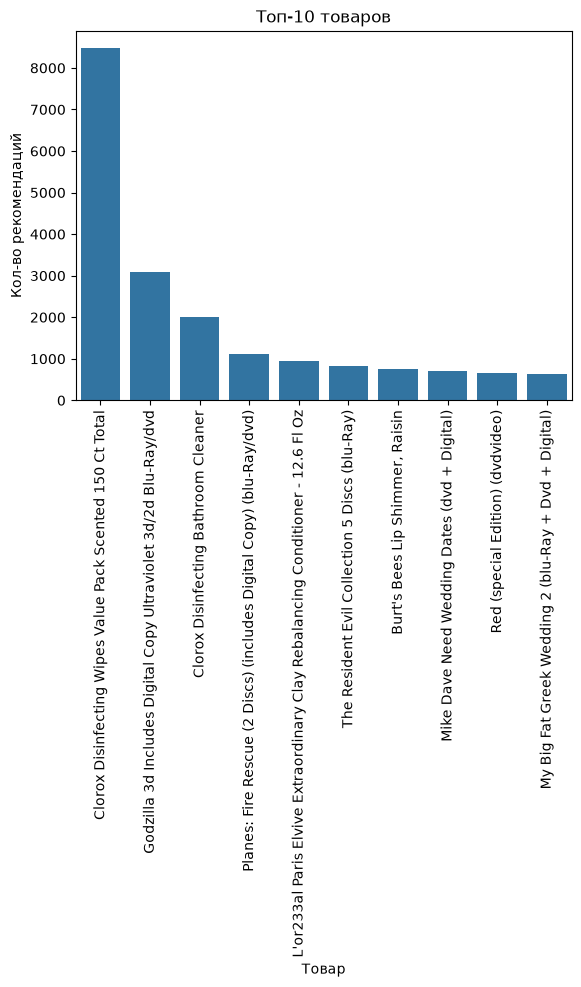

In [11]:
sns.barplot(x=the_most_recomended.index[:10], y=the_most_recomended['reviews_doRecommend'][:10])
plt.xticks(rotation=90)
plt.ylabel('Кол-во рекомендаций')
plt.xlabel('Товар')
plt.title('Топ-10 товаров');

In [13]:
names_of_most_polular_companies = df['manufacturer'].value_counts()[df['manufacturer'].value_counts() > 500].index
mean_rating_for_biggest = df[df['manufacturer'].isin(names_of_most_polular_companies)].groupby('manufacturer').agg({'reviews_rating': 'mean'}).sort_values(by='reviews_rating', ascending=False)

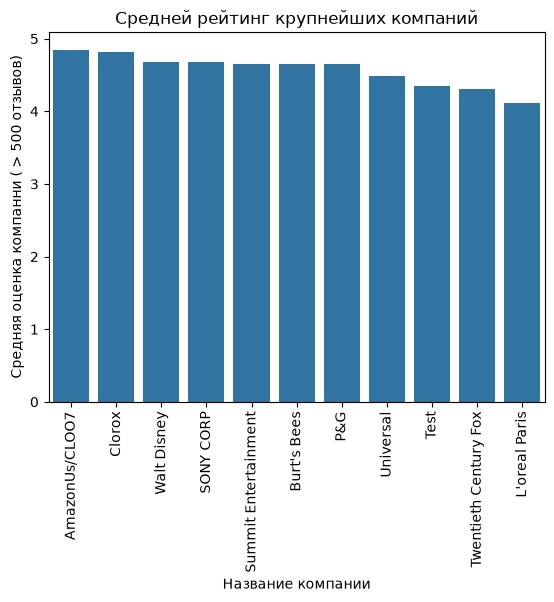

In [14]:
sns.barplot(mean_rating_for_biggest['reviews_rating'])
plt.xticks(rotation=90)
plt.ylabel('Средняя оценка компанни ( > 500 отзывов)')
plt.xlabel('Название компании')
plt.title('Средней рейтинг крупнейших компаний');

## Формирование Ground Truth (Leave-One-Out)

In [27]:
def prepare_train_test_data_final(df, rating_threshold=4):
    """
    Leave-One-Out:
    - В train: все отзывы пользователя (включая нерелевантные) кроме последнего релевантного
    - В test: последний релевантный товар
    """
    df = df.copy()
    df['is_relevant'] = (df['reviews_rating'] >= rating_threshold) | (df['reviews_doRecommend'] == True)
    df = df.sort_values(['reviews_username', 'reviews_date'])
    
    train_list, test_list = [], []
    
    for user, group in df.groupby('reviews_username'):
        group = group.sort_values('reviews_date')
        relevant = group[group['is_relevant'] == True]
        
        if len(relevant) >= 1:
            last_relevant = relevant.iloc[[-1]]
            test_list.append(last_relevant)
            
            # Все отзывы кроме последнего релевантного — в train
            train_items = group[group.index != last_relevant.index[0]]
            if len(train_items) > 0:
                train_list.append(train_items)
    
    train_df = pd.concat(train_list, ignore_index=True) if train_list else pd.DataFrame(columns=df.columns)
    test_df = pd.concat(test_list, ignore_index=True) if test_list else pd.DataFrame(columns=df.columns)
    
    return train_df, test_df

train_df, test_df = prepare_train_test_data_final(df, rating_threshold=4)

# Разделяем test на warm и cold
warm_users = set(train_df['reviews_username'].unique())
test_warm = test_df[test_df['reviews_username'].isin(warm_users)]
test_cold = test_df[~test_df['reviews_username'].isin(warm_users)]

print(f"Train: {len(train_df)} строк, {train_df['reviews_username'].nunique()} пользователей")
print(f"Test всего: {len(test_df)}")
print(f"  Warm (есть история в train): {len(test_warm)} пользователей")
print(f"  Cold start (нет истории): {len(test_cold)} пользователей ({len(test_cold)/len(test_df):.1%})")

Train: 4216 строк, 3068 пользователей
Test всего: 21786
  Warm (есть история в train): 3068 пользователей
  Cold start (нет истории): 18718 пользователей (85.9%)


In [29]:
from surprise import Reader, Dataset, SVD
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

# ===== 1. Popularity Baseline =====
popularity_counts = train_df['name'].value_counts().index.tolist()

def get_popularity_recommendations(user_id, k=10):
    return popularity_counts[:k]

# ===== 2. SVD (Collaborative Filtering) =====
reader = Reader(rating_scale=(1, 5))
data = Dataset.load_from_df(train_df[['reviews_username', 'name', 'reviews_rating']], reader)
trainset = data.build_full_trainset()

svd_model = SVD(n_factors=50, n_epochs=20, lr_all=0.005, reg_all=0.02, random_state=42)
svd_model.fit(trainset)
all_items = train_df['name'].unique().tolist()

def get_svd_recommendations(user_id, k=10):
    user_train_items = set(train_df[train_df['reviews_username'] == user_id]['name'].tolist())
    candidates = [item for item in all_items if item not in user_train_items]
    
    if not candidates:
        return popularity_counts[:k]
    
    predictions = [(item, svd_model.predict(user_id, item).est) for item in candidates]
    predictions.sort(key=lambda x: x[1], reverse=True)
    return [item for item, score in predictions[:k]]

# ===== 3. Content-Based (TF-IDF) =====
df['content_features'] = (
    df['name'].fillna('') + ' ' + 
    df['categories'].fillna('') + ' ' + 
    df['brand'].fillna('')
)
item_profiles = df.drop_duplicates(subset=['name']).set_index('name')['content_features']
tfidf = TfidfVectorizer(stop_words='english')
tfidf_matrix = tfidf.fit_transform(item_profiles)
cosine_sim_matrix = cosine_similarity(tfidf_matrix, tfidf_matrix)
item_indices = pd.Series(item_profiles.index)

def get_content_recommendations(user_id, k=10):
    user_items = train_df[train_df['reviews_username'] == user_id]['name'].tolist()
    
    if not user_items:
        return popularity_counts[:k]
    
    last_item = user_items[-1]
    if last_item not in item_indices.values:
        return popularity_counts[:k]
    
    idx = item_indices[item_indices == last_item].index[0]
    sim_scores = list(enumerate(cosine_sim_matrix[idx]))
    sim_scores = sorted(sim_scores, key=lambda x: x[1], reverse=True)
    
    recommended = []
    for i, score in sim_scores:
        item_name = item_indices.iloc[i]
        if item_name != last_item and item_name not in user_items:
            recommended.append(item_name)
        if len(recommended) >= k:
            break
    
    if len(recommended) < k:
        for item in popularity_counts:
            if item not in recommended and item != last_item:
                recommended.append(item)
            if len(recommended) >= k:
                break
    
    return recommended

In [30]:
def hit_rate_at_k(recommended, actual, k):
    return 1.0 if any(item in recommended[:k] for item in actual) else 0.0

def precision_at_k(recommended, actual, k):
    rec_k = recommended[:k]
    return len(set(rec_k) & set(actual)) / k

def recall_at_k(recommended, actual, k):
    rec_k = recommended[:k]
    return len(set(rec_k) & set(actual)) / len(actual) if len(actual) > 0 else 0.0

def ndcg_at_k(recommended, actual, k):
    rec_k = recommended[:k]
    dcg = sum(1.0 / np.log2(i + 2) for i, item in enumerate(rec_k) if item in actual)
    idcg = sum(1.0 / np.log2(i + 2) for i in range(min(len(actual), k)))
    return dcg / idcg if idcg > 0 else 0.0

def evaluate_model(recommend_func, test_df, k_values=[1, 5, 10]):
    results = {k: {'HR': [], 'Precision': [], 'Recall': [], 'NDCG': []} for k in k_values}
    
    for _, row in test_df.iterrows():
        user_id = row['reviews_username']
        actual_item = row['name']
        recommended = recommend_func(user_id, k=max(k_values))
        
        for k in k_values:
            results[k]['HR'].append(hit_rate_at_k(recommended, [actual_item], k))
            results[k]['Precision'].append(precision_at_k(recommended, [actual_item], k))
            results[k]['Recall'].append(recall_at_k(recommended, [actual_item], k))
            results[k]['NDCG'].append(ndcg_at_k(recommended, [actual_item], k))
    
    return {
        k: {
            'Hit Rate@K': np.mean(results[k]['HR']),
            'Precision@K': np.mean(results[k]['Precision']),
            'Recall@K': np.mean(results[k]['Recall']),
            'NDCG@K': np.mean(results[k]['NDCG'])
        } for k in k_values
    }

In [31]:
k_values = [1, 5, 10]
models = {
    'Popularity Baseline': get_popularity_recommendations,
    'Collaborative Filtering (SVD)': get_svd_recommendations,
    'Content-Based (TF-IDF)': get_content_recommendations
}

print(f"=== Оценка на WARM пользователях (n={len(test_warm)}) ===\n")
warm_results = {}
for model_name, model_func in models.items():
    print(f"Оценка {model_name}...")
    warm_results[model_name] = evaluate_model(model_func, test_warm, k_values)

# Сравнительная таблица
rows = []
for model_name in models.keys():
    for k in [5, 10]:
        row = {
            'Модель': model_name,
            'K': k,
            'Hit Rate@K': f"{warm_results[model_name][k]['Hit Rate@K']:.4f}",
            'Precision@K': f"{warm_results[model_name][k]['Precision@K']:.4f}",
            'Recall@K': f"{warm_results[model_name][k]['Recall@K']:.4f}",
            'NDCG@K': f"{warm_results[model_name][k]['NDCG@K']:.4f}"
        }
        rows.append(row)

comparison_df = pd.DataFrame(rows)
display(comparison_df)

=== Оценка на WARM пользователях (n=3068) ===

Оценка Popularity Baseline...
Оценка Collaborative Filtering (SVD)...
Оценка Content-Based (TF-IDF)...


,Модель,K,Hit Rate@K,Precision@K,Recall@K,NDCG@K
0,Popularity Baseline,5,0.6623,0.1325,0.6623,0.4665
1,Popularity Baseline,10,0.8035,0.0803,0.8035,0.5128
2,Collaborative Filtering (SVD),5,0.1379,0.0276,0.1379,0.0683
3,Collaborative Filtering (SVD),10,0.2311,0.0231,0.2311,0.0988
4,Content-Based (TF-IDF),5,0.2728,0.0546,0.2728,0.2365
5,Content-Based (TF-IDF),10,0.3155,0.0316,0.3155,0.2500


In [32]:
thresholds = [3, 4, 5]
all_threshold_results = {}

for threshold in thresholds:
    print(f"\n--- Порог rating >= {threshold} ---")
    train_t, test_t = prepare_train_test_data_final(df, rating_threshold=threshold)
    
    warm_users_t = set(train_t['reviews_username'].unique())
    test_warm_t = test_t[test_t['reviews_username'].isin(warm_users_t)]
    
    print(f"Warm пользователей: {len(test_warm_t)}")
    
    # Переобучаем SVD для нового train
    data_t = Dataset.load_from_df(train_t[['reviews_username', 'name', 'reviews_rating']], reader)
    svd_t = SVD(n_factors=50, n_epochs=20, lr_all=0.005, reg_all=0.02, random_state=42)
    svd_t.fit(data_t.build_full_trainset())
    
    # Временно подменяем глобальные переменные
    global train_df, svd_model
    train_df, svd_model = train_t, svd_t
    
    threshold_results = {}
    for model_name, model_func in models.items():
        threshold_results[model_name] = evaluate_model(model_func, test_warm_t, k_values)
    
    all_threshold_results[threshold] = threshold_results


--- Порог rating >= 3 ---
Warm пользователей: 3074

--- Порог rating >= 4 ---
Warm пользователей: 3068

--- Порог rating >= 5 ---
Warm пользователей: 3068


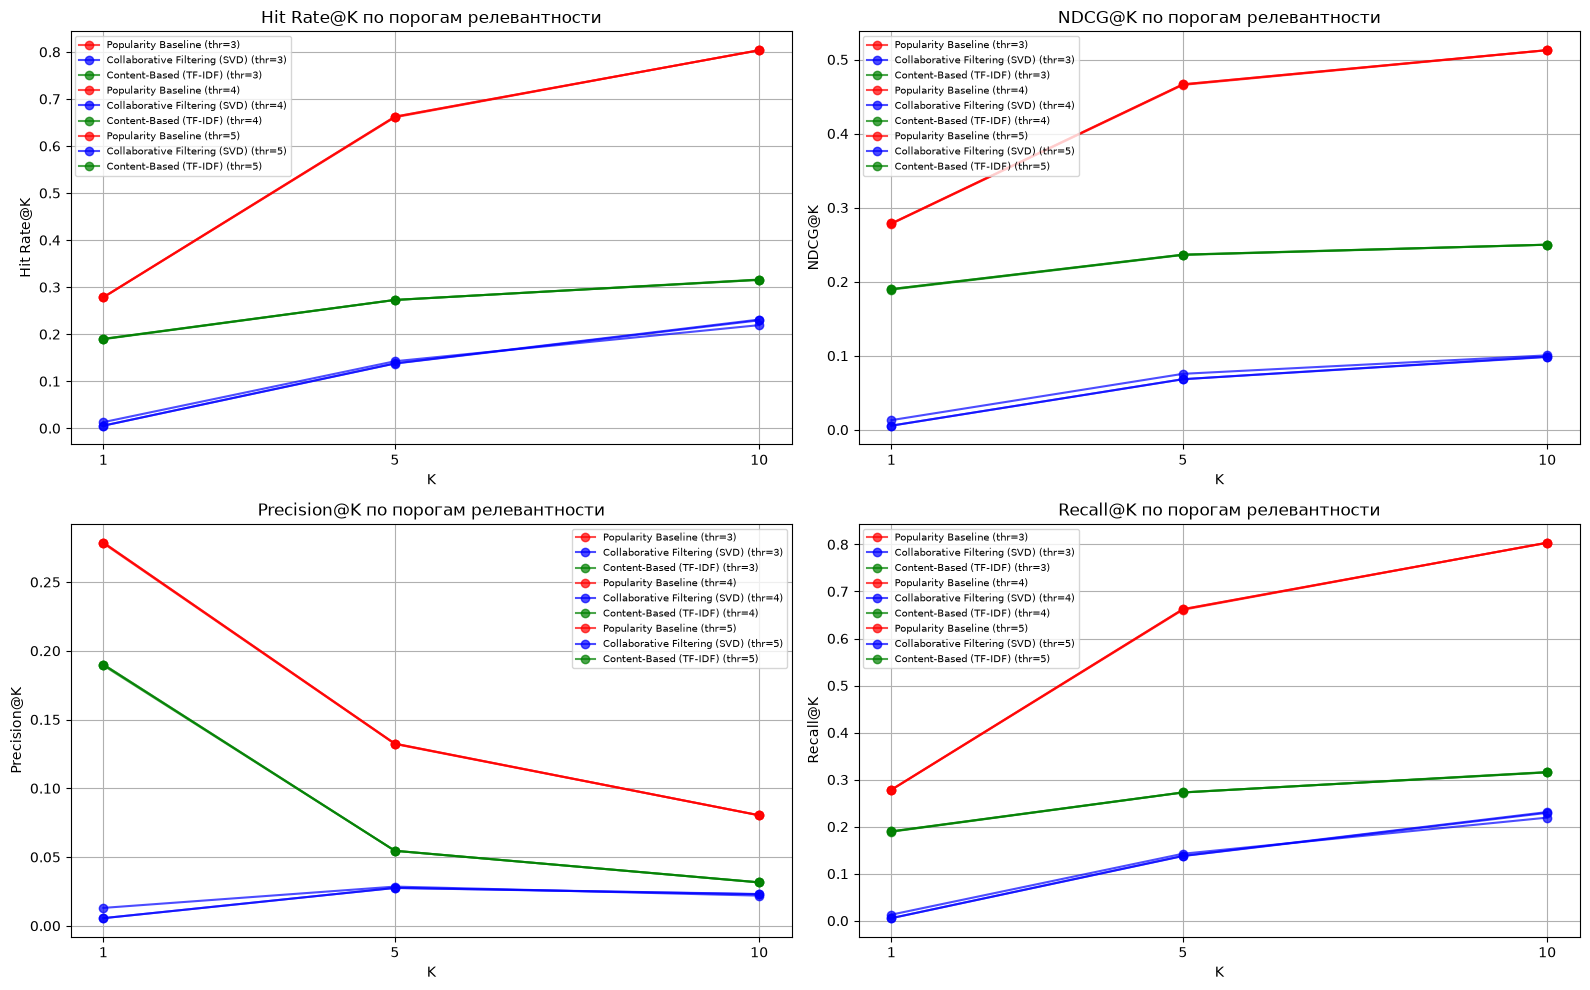

In [33]:
fig, axes = plt.subplots(2, 2, figsize=(16, 10))
metrics = ['Hit Rate@K', 'NDCG@K', 'Precision@K', 'Recall@K']
colors = {'Popularity Baseline': 'red', 'Collaborative Filtering (SVD)': 'blue', 'Content-Based (TF-IDF)': 'green'}

for ax, metric in zip(axes.flatten(), metrics):
    for threshold in thresholds:
        res = all_threshold_results[threshold]
        for model_name in models.keys():
            vals = [res[model_name][k][metric] for k in k_values]
            ax.plot(k_values, vals, marker='o', label=f"{model_name} (thr={threshold})", 
                   color=colors[model_name], alpha=0.7)
    
    ax.set_title(f'{metric} по порогам релевантности')
    ax.set_xlabel('K')
    ax.set_ylabel(metric)
    ax.set_xticks(k_values)
    ax.legend(fontsize=7, loc='best')
    ax.grid(True)

plt.tight_layout()
plt.show()

In [40]:
# Берём 5 случайных пользователей из test_warm
sample_users = test_warm['reviews_username'].drop_duplicates().sample(5, random_state=42).tolist()

rec_table = []
for user in sample_users:
    recs = get_svd_recommendations(user, k=10)
    recs_str = "; ".join(recs)
    rec_table.append({'user_id': user, 'список рекомендованных товаров': recs_str})

final_df = pd.DataFrame(rec_table)
print("| user_id | список рекомендованных товаров |")
print("| --- | --- |")
for _, row in final_df.iterrows():
    user = row['user_id']
    # Заменяем "; " на "<br>" для Markdown-рендеринга
    items = row['список рекомендованных товаров'].replace('; ', '<br>')
    print(f"| {user} | {items} |")

| user_id | список рекомендованных товаров |
| --- | --- |
| sofi | Clorox Disinfecting Wipes Value Pack Scented 150 Ct Total<br>Avery174 Ready Index Contemporary Table Of Contents Divider, 1-8, Multi, Letter<br>Lysol Concentrate Deodorizing Cleaner, Original Scent<br>Bisquick Original Pancake And Baking Mix - 40oz<br>Planes: Fire Rescue (2 Discs) (includes Digital Copy) (blu-Ray/dvd)<br>Yes To Carrots Nourishing Body Wash<br>Australian Gold Exotic Blend Lotion, SPF 4<br>Stargate (ws) (ultimate Edition) (director's Cut) (dvdvideo)<br>Burt's Bees Lip Shimmer, Raisin<br>Vaseline Intensive Care Healthy Hands Stronger Nails |
| m52003 | Avery174 Ready Index Contemporary Table Of Contents Divider, 1-8, Multi, Letter<br>Bisquick Original Pancake And Baking Mix - 40oz<br>Stargate (ws) (ultimate Edition) (director's Cut) (dvdvideo)<br>Lysol Concentrate Deodorizing Cleaner, Original Scent<br>Vaseline Intensive Care Lip Therapy Cocoa Butter<br>Burt's Bees Lip Shimmer, Raisin<br>Chester's Cheese 

### Аналитический вывод

**1. Характеристика данных.** Датасет крайне разрежен: среднее число отзывов на 
пользователя составляет 1.18, 86% пользователей имеют ровно 1 отзыв. Даже после 
отбора «тёплых» пользователей (с историей в train) на каждого приходится в среднем 
~1.4 взаимодействия. Это фундаментально ограничивает применимость персонализированных 
подходов и объясняет доминирование Popularity Baseline.

**2. Сравнение подходов на тёплом сегменте (n=3068, порог rating >= 4):**

| Модель | HR@5 | HR@10 | NDCG@5 | NDCG@10 | Precision@5 | Recall@5 |
|---|---|---|---|---|---|---|
| Popularity Baseline | 0.662 | 0.804 | 0.467 | 0.513 | 0.133 | 0.662 |
| Content-Based (TF-IDF) | 0.273 | 0.316 | 0.237 | 0.250 | 0.055 | 0.273 |
| Collaborative Filtering (SVD) | 0.138 | 0.231 | 0.068 | 0.099 | 0.028 | 0.138 |

- **Popularity Baseline** показал наилучшие результаты по всем метрикам. 
  Это объясняется двумя факторами: (а) сильным смещением распределения рейтингов 
  в сторону высоких оценок — релевантные товары в test с высокой вероятностью 
  оказываются популярными; (б) недостаточным объёмом сигнала для обучения 
  персонализированных моделей.
- **Content-Based (TF-IDF)** занял второе место. Модель использует признаки товара 
  (название, категория, бренд), которые не зависят от плотности пользовательской 
  истории, поэтому лучше адаптирована к разреженным данным.
- **Collaborative Filtering (SVD)** показал наименьшие метрики. Матричная 
  факторизация требует достаточного количества взаимодействий для выявления 
  латентных факторов; при ~1-2 отзывах на пользователя модель не успевает обучиться.

**3. Устойчивость к порогам релевантности (по графикам):**

- **Hit Rate@K и Recall@K** формально растут при снижении порога с 5 до 3 
  (для Popularity: HR@10 с ~0.22 до ~0.80), поскольку расширяется множество 
  «релевантных» товаров. Однако это не означает улучшения качества — модель 
  просто чаще попадает в более широкий целевой набор.
- **Precision@K** ведёт себя противоположно: при пороге rating=5 Popularity 
  показывает Precision@1 ≈ 0.28 (самый любимый товар пользователя часто является 
  глобально популярным), тогда как при пороге rating>=3 Precision@1 падает до ~0.10.
- **NDCG@K** — наиболее информативная метрика, учитывающая ранжирование. 
  Content-Based показал наибольшую устойчивость к изменению порога (кривые 
  практически сливаются), что говорит о стабильности контентных признаков. 
  Popularity, напротив, сильно зависит от порога.
- **SVD остаётся худшим на всех порогах** — проблема не в определении 
  релевантности, а в недостатке данных для обучения.

**4. Вывод о применимости подходов.**
- **Popularity Baseline** лучше всего работает при высокой разреженности данных 
  и смещённом распределении рейтингов — типичная ситуация для новых или 
  нишевых интернет-магазинов.
- **Content-Based** универсален: работает и на cold start, и на тёплых 
  пользователях, устойчив к изменению порога релевантности. Рекомендуется 
  как базовый персонализированный подход.
- **Collaborative Filtering (SVD)** требует плотной матрицы взаимодействий 
  и даёт преимущества только при достаточном объёме данных (тысячи отзывов 
  на активного пользователя).